## 1. Introduction & Objectives

### Project Overview & Business Problem

As a Junior Data Scientist assisting a publishing analytics team, this project aims to provide data-driven insights to help bookstores and online retailers optimize their catalog offerings. By collecting real-world product data from *Books to Scrape* (books.toscrape.com), we seek to understand the underlying factors influencing book prices and ratings across different genres and catalog features.

### Core Objectives

1. **Data Acquisition:** Scrape at least 200 product listings (or full catalog) using `BeautifulSoup` to extract key book features including title, price (£), star rating (1–5), and stock availability.
2. **Data Processing & Cleaning:** Clean raw text fields, extract numerical values, handle missing or inconsistent entries, and perform feature engineering (e.g., extracting title length and word counts).
3. **Exploratory Data Analysis (EDA):** Analyze price distributions, examine rating patterns, and create visual representations to uncover pricing behaviors and trends across the catalog.
4. **Predictive Modeling:** Build and evaluate a Linear Regression model to predict book prices based on derived title and catalog features.
5. **Business Insights & Recommendations:** Produce actionable strategic guidance for retailers, publishers, and consumers based on quantitative findings.

## 2. Data Scraping & Extraction (BeautifulSoup)

In [ ]:
import time
from urllib.parse import urljoin

import requests
from bs4 import BeautifulSoup
import pandas as pd

START_URL = "https://books.toscrape.com/catalogue/page-1.html"

In [ ]:
rating_map = {
    "One": 1,
    "Two": 2,
    "Three": 3,
    "Four": 4,
    "Five": 5
}

In [ ]:
books_data = []
visited_pages = set()
current_url = START_URL = "http://books.toscrape.com/catalogue/page-1.html"


with requests.Session() as session:
    while current_url:
        if current_url in visited_pages:
            raise RuntimeError(f"Pagination loop detected: {current_url}")

        response = session.get(current_url, timeout=30)
        response.raise_for_status()

        # Parse bytes so BeautifulSoup can detect the HTML encoding.
        soup = BeautifulSoup(response.content, "html.parser")
        articles = soup.select("article.product_pod")

        if not articles:
            raise ValueError(f"No book listings found: {current_url}")

        visited_pages.add(current_url)

        for article in articles:
            title_link = article.select_one("h3 a")
            price_tag = article.select_one("p.price_color")
            rating_tag = article.select_one("p.star-rating")
            availability_tag = article.select_one("p.availability")

            rating_word = next(
                (
                    cls
                    for cls in rating_tag.get("class", [])
                    if cls in rating_map
                ),
                None
            )

            books_data.append({
                "title": title_link["title"].strip(),
                "price_raw": price_tag.get_text(strip=True),
                "rating_word": rating_word,
                "rating": rating_map.get(rating_word),
                "availability_raw": availability_tag.get_text(
                    " ", strip=True
                ),
                "relative_url": title_link["href"],
                "product_url": urljoin(
                    current_url, title_link["href"]
                )
            })

        print(
            f"Page {len(visited_pages)} complete — "
            f"{len(books_data)} books collected"
        )

        next_link = soup.select_one("li.next a")
        current_url = (
            urljoin(current_url, next_link["href"])
            if next_link
            else None
        )

        if current_url:
            time.sleep(0.3)

df_raw = pd.DataFrame(books_data)

print(f"\nCollected {len(df_raw)} rows.")
print(f"Unique products: {df_raw['product_url'].nunique()}")
print(f"Duplicate URLs: {df_raw['product_url'].duplicated().sum()}")

Page 1 complete — 20 books collected
Page 2 complete — 40 books collected
Page 3 complete — 60 books collected
Page 4 complete — 80 books collected
Page 5 complete — 100 books collected
Page 6 complete — 120 books collected
Page 7 complete — 140 books collected
Page 8 complete — 160 books collected
Page 9 complete — 180 books collected
Page 10 complete — 200 books collected
Page 11 complete — 220 books collected
Page 12 complete — 240 books collected
Page 13 complete — 260 books collected
Page 14 complete — 280 books collected
Page 15 complete — 300 books collected
Page 16 complete — 320 books collected
Page 17 complete — 340 books collected
Page 18 complete — 360 books collected
Page 19 complete — 380 books collected
Page 20 complete — 400 books collected
Page 21 complete — 420 books collected
Page 22 complete — 440 books collected
Page 23 complete — 460 books collected
Page 24 complete — 480 books collected
Page 25 complete — 500 books collected
Page 26 complete — 520 books collected

In [ ]:
assert df_raw["product_url"].nunique() >= 200, (
    "The project requires at least 200 unique books."
)

display(df_raw.head())

,title,price_raw,rating_word,rating,availability_raw,relative_url,product_url
0,A Light in the Attic,£51.77,Three,3,In stock,a-light-in-the-attic_1000/index.html,http://books.toscrape.com/catalogue/a-light-in...
1,Tipping the Velvet,£53.74,One,1,In stock,tipping-the-velvet_999/index.html,http://books.toscrape.com/catalogue/tipping-th...
2,Soumission,£50.10,One,1,In stock,soumission_998/index.html,http://books.toscrape.com/catalogue/soumission...
3,Sharp Objects,£47.82,Four,4,In stock,sharp-objects_997/index.html,http://books.toscrape.com/catalogue/sharp-obje...
4,Sapiens: A Brief History of Humankind,£54.23,Five,5,In stock,sapiens-a-brief-history-of-humankind_996/index...,http://books.toscrape.com/catalogue/sapiens-a-...


## 3. Data Cleaning & Wrangling

In [ ]:
import numpy as np
import re

df = df_raw.copy()

# 1. Clean Price: convert "£51.77" -> 51.77 (float)
df['price'] = df['price_raw'].apply(lambda x: float(re.sub(r'[^0-9.]', '', x)))

# 2. Extract Stock Availability
df['in_stock'] = df['availability_raw'].apply(lambda x: 1 if 'In stock' in x else 0)

# 3. Feature Engineering from Title
df['title_length'] = df['title'].apply(len)
df['word_count'] = df['title'].apply(lambda x: len(x.split()))

# Save Clean Dataset to CSV (Deliverable #2)
df.to_csv("books_scraped_clean.csv", index=False)

checks = pd.Series({
    "Missing or blank titles": (
        df["title"].isna() | df["title"].eq("")
    ).sum(),
    "Missing or invalid prices": df["price"].isna().sum(),
    "Nonpositive prices": df["price"].le(0).sum(),
    "Missing or invalid ratings": df["rating"].isna().sum(),
    "Unknown availability": df["in_stock"].isna().sum(),
    "Duplicate product URLs": df["relative_url"].duplicated().sum()
})

print(checks)

# 4. Print dataset
print(df.head())

Missing or blank titles       0
Missing or invalid prices     0
Nonpositive prices            0
Missing or invalid ratings    0
Unknown availability          0
Duplicate product URLs        0
dtype: int64
                                   title price_raw rating_word  rating  \
0                   A Light in the Attic    £51.77       Three       3   
1                     Tipping the Velvet    £53.74         One       1   
2                             Soumission    £50.10         One       1   
3                          Sharp Objects    £47.82        Four       4   
4  Sapiens: A Brief History of Humankind    £54.23        Five       5   

  availability_raw                                       relative_url  \
0         In stock               a-light-in-the-attic_1000/index.html   
1         In stock                  tipping-the-velvet_999/index.html   
2         In stock                          soumission_998/index.html   
3         In stock                       sharp-objects_997

## 4. Exploratory Data Analysis & Visualizations

Rows excluded from charts: 0


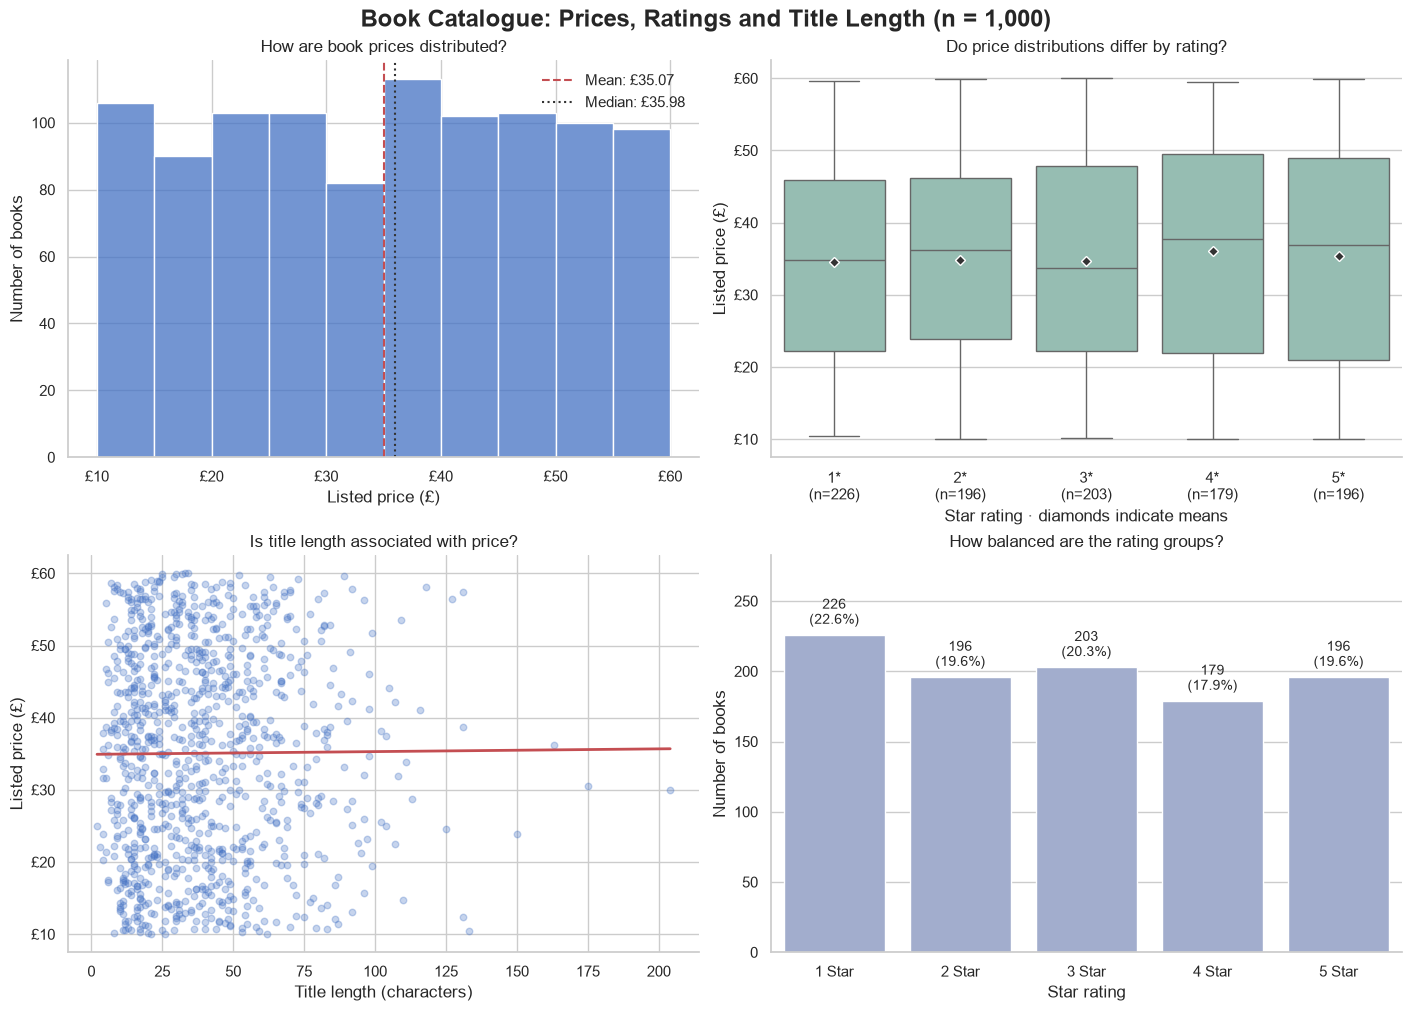

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import StrMethodFormatter

# Prepare a separate plotting dataset
plot_df = df[["price", "rating", "title_length"]].copy()

for column in plot_df.columns:
    plot_df[column] = pd.to_numeric(
        plot_df[column], errors="coerce"
    )

plot_df = plot_df.replace([np.inf, -np.inf], np.nan)

# Retain valid prices and ratings for these charts
valid_rows = (
    plot_df["price"].gt(0)
    & plot_df["rating"].isin([1, 2, 3, 4, 5])
)

print(f"Rows excluded from charts: {(~valid_rows).sum()}")
plot_df = plot_df.loc[valid_rows].copy()

if plot_df.empty:
    raise ValueError("No valid observations available for plotting.")

sns.set_theme(style="whitegrid", context="notebook")

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 10),
    constrained_layout=True
)

fig.suptitle(
    f"Book Catalogue: Prices, Ratings and Title Length "
    f"(n = {len(plot_df):,})",
    fontsize=17,
    fontweight="bold"
)

# 1. Price distribution
ax = axes[0, 0]

sns.histplot(
    data=plot_df,
    x="price",
    binwidth=5,
    color="#4472C4",
    edgecolor="white",
    ax=ax
)

ax.axvline(
    plot_df["price"].mean(),
    color="#C44E52",
    linestyle="--",
    label=f"Mean: £{plot_df['price'].mean():.2f}"
)

ax.axvline(
    plot_df["price"].median(),
    color="#333333",
    linestyle=":",
    label=f"Median: £{plot_df['price'].median():.2f}"
)

ax.set(
    title="How are book prices distributed?",
    xlabel="Listed price (£)",
    ylabel="Number of books"
)
ax.xaxis.set_major_formatter(StrMethodFormatter("£{x:.0f}"))
ax.legend(frameon=False)

# 2. Price distributions by rating
ax = axes[0, 1]
rating_order = [1, 2, 3, 4, 5]

sns.boxplot(
    data=plot_df,
    x="rating",
    y="price",
    order=rating_order,
    color="#8FC4B5",
    showmeans=True,
    meanprops={
        "marker": "D",
        "markerfacecolor": "#333333",
        "markeredgecolor": "white",
        "markersize": 5
    },
    ax=ax
)

group_counts = (
    plot_df["rating"]
    .value_counts()
    .reindex(rating_order, fill_value=0)
)

ax.set_xticks(range(5))
ax.set_xticklabels([
    f"{rating}*\n(n={group_counts.loc[rating]})"
    for rating in rating_order
])

ax.set(
    title="Do price distributions differ by rating?",
    xlabel="Star rating · diamonds indicate means",
    ylabel="Listed price (£)"
)
ax.yaxis.set_major_formatter(StrMethodFormatter("£{x:.0f}"))

# 3. Title length versus price
ax = axes[1, 0]

title_df = plot_df.loc[
    plot_df["title_length"].ge(0)
].dropna(subset=["title_length", "price"])

sns.regplot(
    data=title_df,
    x="title_length",
    y="price",
    ci=None,
    scatter_kws={
        "alpha": 0.30,
        "s": 22,
        "color": "#4472C4"
    },
    line_kws={"color": "#C44E52", "linewidth": 2},
    ax=ax
)

ax.set(
    title="Is title length associated with price?",
    xlabel="Title length (characters)",
    ylabel="Listed price (£)"
)
ax.yaxis.set_major_formatter(StrMethodFormatter("£{x:.0f}"))

# 4. Rating frequency
ax = axes[1, 1]

sns.countplot(
    data=plot_df,
    x="rating",
    order=rating_order,
    color="#9BA9D4",
    ax=ax
)

ax.set_xticks(range(5))
ax.set_xticklabels([f"{rating} Star" for rating in rating_order])

for bar, count in zip(ax.patches, group_counts):
    percentage = 100 * count / len(plot_df)
    ax.annotate(
        f"{count:,}\n({percentage:.1f}%)",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom",
        xytext=(0, 5),
        textcoords="offset points",
        fontsize=10
    )

ax.set_ylim(0, max(group_counts.max() * 1.25, 1))
ax.set(
    title="How balanced are the rating groups?",
    xlabel="Star rating",
    ylabel="Number of books"
)

sns.despine(fig=fig)
plt.show()

## 5. Linear Regression Predictive Model

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# 1. Define features and target
features = ["rating", "title_length", "word_count"]

model_df = df[features + ["price"]].copy()

# Ensure numeric values; invalid entries become missing
for column in model_df.columns:
    model_df[column] = pd.to_numeric(
        model_df[column], errors="coerce"
    )

model_df = model_df.replace([np.inf, -np.inf], np.nan)

# Missing or invalid targets cannot be used for supervised training
valid_target = model_df["price"].notna() & model_df["price"].gt(0)

print(f"Rows excluded for invalid target: {(~valid_target).sum()}")
model_df = model_df.loc[valid_target].copy()

X = model_df[features]
y = model_df["price"]

# 2. Split before fitting preprocessing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# 3. Linear regression pipeline
model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("regression", LinearRegression())
])

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

# 4. Baseline: always predict the training-set mean price
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

# 5. Evaluate both models
def evaluate_predictions(actual, predicted):
    return {
        "MAE (£)": mean_absolute_error(actual, predicted),
        "RMSE (£)": np.sqrt(
            mean_squared_error(actual, predicted)
        ),
        "R²": r2_score(actual, predicted)
    }

results = pd.DataFrame({
    "Mean-price baseline": evaluate_predictions(
        y_test, baseline_pred
    ),
    "Linear regression": evaluate_predictions(
        y_test, y_pred
    )
}).T

print(f"Training observations: {len(X_train)}")
print(f"Test observations: {len(X_test)}")
display(results.round(4))

# 6. Inspect model coefficients
regression = model.named_steps["regression"]

coefficients = pd.DataFrame({
    "Feature": features,
    "Coefficient (£ per unit)": regression.coef_
})

display(coefficients.round(4))
print(f"Intercept: £{regression.intercept_:.4f}")

Rows excluded for invalid target: 0
Training observations: 800
Test observations: 200


,MAE (£),RMSE (£),R²
Mean-price baseline,12.6619,14.5305,-0.0051
Linear regression,12.6892,14.5738,-0.0111


,Feature,Coefficient (£ per unit)
0,rating,0.3697
1,title_length,-0.1096
2,word_count,0.7912


Intercept: £33.1770


## 5.1 Model diagnostic plots

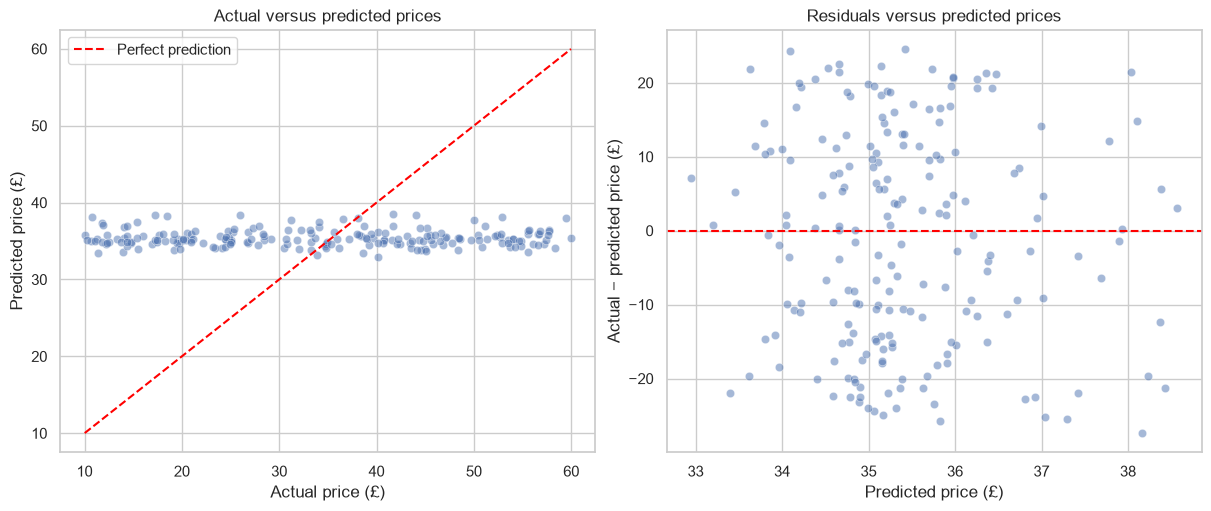

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

residuals = y_test.to_numpy() - y_pred

fig, axes = plt.subplots(
    1, 2, figsize=(12, 5), constrained_layout=True
)

# Actual versus predicted
sns.scatterplot(
    x=y_test.to_numpy(),
    y=y_pred,
    alpha=0.5,
    ax=axes[0]
)

lower = min(y_test.min(), y_pred.min())
upper = max(y_test.max(), y_pred.max())

axes[0].plot(
    [lower, upper],
    [lower, upper],
    "--",
    color="red",
    label="Perfect prediction"
)

axes[0].set(
    title="Actual versus predicted prices",
    xlabel="Actual price (£)",
    ylabel="Predicted price (£)"
)
axes[0].legend()

# Residuals versus predicted
sns.scatterplot(
    x=y_pred,
    y=residuals,
    alpha=0.5,
    ax=axes[1]
)

axes[1].axhline(0, linestyle="--", color="red")
axes[1].set(
    title="Residuals versus predicted prices",
    xlabel="Predicted price (£)",
    ylabel="Actual − predicted price (£)"
)

plt.show()

## 6. Summary & Recommendations

### Summary of Findings


This project collected and analysed 1,000 books from Books to Scrape. Data preparation included converting prices into numeric values, converting star ratings into numeric scores, encoding stock availability, and creating title-length and word-count features.

Listed prices ranged from £10.00 to £59.99. Validation found no missing cleaned prices or duplicate product URLs. All collected books were marked as in stock, so this indicator was excluded from modelling because it contained no variation.

A linear regression model was developed using rating, title length, and title word count. The dataset was split into 800 training records and 200 test records.

The regression performed slightly worse than the baseline. The selected features therefore provided little predictive value on this test split. The model’s predictions differed from actual prices by approximately £12.69 on average.

### Recommendations

1. Do not deploy the current model for pricing decisions
The model did not improve on a simple average-price prediction. It should be treated as a demonstration of the analytical workflow rather than a reliable pricing tool.

2. Expand the dataset before further modelling
Collect category, stock quantity, and descriptions from product pages. These would support richer catalogue analysis and allow additional predictors to be tested, although improvement is not guaranteed.

For a real commercial application, also investigate features such as format, page count, publication date, publisher, sales volume, and discounts.

3. Strengthen model evaluation
Use cross-validation within the training data to assess whether performance is consistent across different samples. Continue comparing models against the same baseline and reserve the test set for final evaluation.

Because title length and word count capture related information, compare models using each feature separately as well as together.

4. Avoid unsupported commercial conclusions
The analysis does not establish that ratings or title characteristics cause changes in price. Retailers and publishers should not adjust prices based on these coefficients, and buyers should not interpret this model’s predictions as measures of fair value.

5. Complete the project’s data coverage
Before final submission, extract stock quantities where shown and document missing-value checks, scraping coverage, and limitations. Category-level analysis would also strengthen the project’s connection to its catalogue-comparison objective.

### Conclusion

The project successfully demonstrates data collection, cleaning, feature engineering, and baseline-based model evaluation, but the current model is not suitable for practical price estimation. The key lesson is that a correctly implemented model is not necessarily a useful one: its value must be established through evaluation against a simple alternative.

In [ ]:
pip install scikit-learn


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
pip install matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip
